<a href="https://colab.research.google.com/github/Antawni/SDS-510-Module-3-/blob/main/Module_3_Essentials.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mariapushkareva/phoenix-crime-data")

print("Path to dataset files:", path)

100%|██████████| 2.43M/2.43M [00:00<00:00, 122MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/mariapushkareva/phoenix-crime-data/versions/1


In [2]:
import os

os.listdir(path)

['crimestat (1).csv']

In [3]:
import pandas as pd

df = pd.read_csv(
    os.path.join(path, "crimestat (1).csv"),
    engine="python",
    on_bad_lines="skip"
)

df.head()

,INC NUMBER,OCCURRED ON,OCCURRED TO,UCR CRIME CATEGORY,100 BLOCK ADDR,ZIP,PREMISE TYPE
0,201600000052855,11/01/2015 00:00,01/09/2016 00:00,MOTOR VEHICLE THEFT,N 43RD AVE & W CACTUS RD,85029.0,SINGLE FAMILY HOUSE
1,201600000594484,11/01/2015 00:00,NaN,RAPE,13XX E ALMERIA RD,85006.0,SINGLE FAMILY HOUSE
2,201500002102327,11/01/2015 00:00,11/01/2015 09:00,LARCENY-THEFT,51XX N 15TH ST,85014.0,APARTMENT
3,201500002101405,11/01/2015 00:00,11/01/2015 05:00,MOTOR VEHICLE THEFT,102XX W MEDLOCK AVE,85307.0,SINGLE FAMILY HOUSE
4,201500002102668,11/01/2015 00:00,11/01/2015 11:50,MOTOR VEHICLE THEFT,69XX W WOOD ST,85043.0,SINGLE FAMILY HOUSE


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131676 entries, 0 to 131675
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   INC NUMBER          131676 non-null  object 
 1   OCCURRED ON         131360 non-null  object 
 2   OCCURRED TO         93174 non-null   object 
 3   UCR CRIME CATEGORY  131676 non-null  object 
 4   100 BLOCK ADDR      131676 non-null  object 
 5   ZIP                 131673 non-null  float64
 6   PREMISE TYPE        130919 non-null  object 
dtypes: float64(1), object(6)
memory usage: 7.0+ MB


In [5]:
df.columns

Index(['INC NUMBER', 'OCCURRED ON', 'OCCURRED TO', 'UCR CRIME CATEGORY',
       '100 BLOCK ADDR', 'ZIP', 'PREMISE TYPE'],
      dtype='object')

In [6]:
df['UCR CRIME CATEGORY'].value_counts()

,count
UCR CRIME CATEGORY,
LARCENY-THEFT,66216
BURGLARY,23647
MOTOR VEHICLE THEFT,14391
DRUG OFFENSE,9572
AGGRAVATED ASSAULT,9306
ROBBERY,5640
RAPE,1981
ARSON,634
MURDER AND NON-NEGLIGENT MANSLAUGHTER,289


In [7]:
df['ZIP'].value_counts().head(10)

,count
ZIP,
85015.0,6963
85008.0,6320
85009.0,5513
85041.0,5477
85051.0,5389
85017.0,5355
85035.0,4752
85043.0,4331
85032.0,4301


In [8]:
df.groupby('ZIP')['UCR CRIME CATEGORY'].value_counts()

ZIP      UCR CRIME CATEGORY 
85003.0  LARCENY-THEFT          758
         DRUG OFFENSE           194
         BURGLARY               179
         MOTOR VEHICLE THEFT    128
         AGGRAVATED ASSAULT     120
                               ... 
85395.0  AGGRAVATED ASSAULT       1
         RAPE                     1
85396.0  LARCENY-THEFT            2
         BURGLARY                 1
         MOTOR VEHICLE THEFT      1
Name: count, Length: 561, dtype: int64

In [9]:
df['PREMISE TYPE'].value_counts().head(10)

,count
PREMISE TYPE,
SINGLE FAMILY HOUSE,25329
APARTMENT,14957
PARKING LOT,14148
STREET / ROADWAY / ALLEY / SIDEWALK,11596
RETAIL BUSINESS,10852
VEHICLE,6844
DRIVEWAY,4609
CONVENIENCE MARKET / STORE,4270
DEPARTMENT / DISCOUNT STORE,3822


In [10]:
violent = ['AGGRAVATED ASSAULT', 'ROBBERY', 'RAPE',
           'MURDER AND NON-NEGLIGENT MANSLAUGHTER']

df['CRIME GROUP'] = df['UCR CRIME CATEGORY'].apply(
    lambda x: 'Violent' if x in violent else 'Other'
)

df['CRIME GROUP'].value_counts()

,count
CRIME GROUP,
Other,114460
Violent,17216


In [11]:
df['OCCURRED ON'] = pd.to_datetime(
    df['OCCURRED ON'], errors='coerce'
)
df['OCCURRED ON'].dt.year.value_counts().sort_index()

,count
OCCURRED ON,
2015.0,10124
2016.0,63226
2017.0,58010


Starting at cell 13 this is the essentials badge section for Module 3

In [13]:
import pandas as pd

population = pd.read_csv('census_data_all_zipcode.csv')

population.head()

/tmp/ipykernel_2674/1536514119.py:3: DtypeWarning: Columns (77,143) have mixed types. Specify dtype option on import or set low_memory=False.
  population = pd.read_csv('census_data_all_zipcode.csv')


,zipcode,city_name,state_code,state,primary_county_name,timezone,area_codes,latitude,longitude,zipcode_type,...,race_other_pct,race_two_plus_pct,hispanic_latino_pct,non_hispanic_white_pct,pop_age_20_24_pct,pop_age_25_34_pct,pop_age_35_44_pct,pop_age_45_54_pct,pop_age_55_59_pct,pop_age_60_64_pct
0,601,Adjuntas,PR,Puerto Rico,Adjuntas Municipio,America/Puerto_Rico,"787, 939",18.16,-66.72,STANDARD,...,0.0,10.3,99.3,0.4,5.1,12.3,12.3,12.6,6.7,8.2
1,602,Aguada,PR,Puerto Rico,Aguada Municipio,America/Puerto_Rico,"787, 939",18.38,-67.18,STANDARD,...,0.0,66.2,97.2,1.5,6.0,12.0,12.9,12.7,7.1,8.9
2,603,Aguadilla,PR,Puerto Rico,Aguadilla Municipio,America/Puerto_Rico,"787, 939",18.43,-67.15,STANDARD,...,0.0,11.5,98.4,1.1,6.3,11.9,11.3,12.9,6.7,7.2
3,606,Maricao,PR,Puerto Rico,Maricao Municipio,America/Puerto_Rico,"787, 939",18.18,-66.98,STANDARD,...,0.0,7.7,99.7,0.1,3.7,7.8,15.5,12.7,6.3,8.8
4,610,Anasco,PR,Puerto Rico,Anasco Municipio,America/Puerto_Rico,"787, 939",18.28,-67.14,STANDARD,...,0.0,70.1,96.4,1.5,6.2,13.4,11.9,13.8,6.9,7.5


In [14]:
zip_codes = ['85015', '85008', '85009', '85041', '85051',
             '85017', '85035', '85043', '85032', '85033']

In [16]:
population.columns

Index(['zipcode', 'city_name', 'state_code', 'state', 'primary_county_name',
       'timezone', 'area_codes', 'latitude', 'longitude', 'zipcode_type',
       ...
       'race_other_pct', 'race_two_plus_pct', 'hispanic_latino_pct',
       'non_hispanic_white_pct', 'pop_age_20_24_pct', 'pop_age_25_34_pct',
       'pop_age_35_44_pct', 'pop_age_45_54_pct', 'pop_age_55_59_pct',
       'pop_age_60_64_pct'],
      dtype='object', length=246)

In [17]:
population['zipcode'] = population['zipcode'].astype(str).str.replace(r'\.0$', '', regex=True).str.zfill(5)

selected_zips = population[population['zipcode'].isin(zip_codes)]

selected_zips

,zipcode,city_name,state_code,state,primary_county_name,timezone,area_codes,latitude,longitude,zipcode_type,...,race_other_pct,race_two_plus_pct,hispanic_latino_pct,non_hispanic_white_pct,pop_age_20_24_pct,pop_age_25_34_pct,pop_age_35_44_pct,pop_age_45_54_pct,pop_age_55_59_pct,pop_age_60_64_pct
29630,85008,Phoenix,AZ,Arizona,Maricopa County,America/Phoenix,"480, 602",33.46,-111.98,STANDARD,...,0.0,42.6,57.6,24.7,9.9,21.8,14.4,11.8,5.5,3.4
29631,85009,Phoenix,AZ,Arizona,Maricopa County,America/Phoenix,602,33.44,-112.13,STANDARD,...,0.0,41.9,81.8,8.3,9.0,15.8,14.2,12.5,5.0,4.9
29635,85015,Phoenix,AZ,Arizona,Maricopa County,America/Phoenix,602,33.50,-112.10,STANDARD,...,0.0,32.9,52.6,23.6,8.3,18.6,14.2,11.4,5.4,4.4
29637,85017,Phoenix,AZ,Arizona,Maricopa County,America/Phoenix,602,33.50,-112.12,STANDARD,...,0.0,36.0,58.8,21.2,12.6,12.5,12.6,11.5,4.5,2.6
29650,85032,Phoenix,AZ,Arizona,Maricopa County,America/Phoenix,602,33.62,-112.00,STANDARD,...,0.0,21.1,31.8,55.3,5.9,18.1,14.0,12.4,6.5,6.0
29651,85033,Phoenix,AZ,Arizona,Maricopa County,America/Phoenix,623,33.49,-112.21,STANDARD,...,0.0,41.2,82.4,9.9,8.7,16.2,14.4,10.6,4.2,4.2
29653,85035,Phoenix,AZ,Arizona,Maricopa County,America/Phoenix,"602, 623",33.47,-112.19,STANDARD,...,0.0,38.6,77.4,7.4,9.6,16.1,12.8,10.5,4.3,3.6
29656,85041,Phoenix,AZ,Arizona,Maricopa County,America/Phoenix,602,33.38,-112.11,STANDARD,...,0.0,33.1,65.4,13.0,7.8,13.6,14.4,12.3,4.8,6.6
29658,85043,Phoenix,AZ,Arizona,Maricopa County,America/Phoenix,"602, 623",33.42,-112.20,STANDARD,...,0.0,37.5,72.7,11.0,6.9,17.3,14.3,12.0,5.1,3.4
29663,85051,Phoenix,AZ,Arizona,Maricopa County,America/Phoenix,"602, 623",33.55,-112.13,STANDARD,...,0.0,28.7,48.7,31.3,7.3,16.8,14.5,10.7,5.6,5.9


In [19]:
selected_zips[['zipcode', 'pop_total_est']]

,zipcode,pop_total_est
29630,85008,59716
29631,85009,52064
29635,85015,41490
29637,85017,46129
29650,85032,70839
29651,85033,57591
29653,85035,53424
29656,85041,63862
29658,85043,41331
29663,85051,45768


In [20]:
selected_zips[['zipcode', 'pop_total_est']].sort_values(
    by='pop_total_est', ascending=False
)

,zipcode,pop_total_est
29650,85032,70839
29656,85041,63862
29630,85008,59716
29651,85033,57591
29653,85035,53424
29631,85009,52064
29637,85017,46129
29663,85051,45768
29635,85015,41490
29658,85043,41331


In [23]:
crime_counts.sort_values(by='crimes', ascending=False).head(10)

,ZIP,crimes
9,85015.0,6963
4,85008.0,6320
5,85009.0,5513
29,85041.0,5477
36,85051.0,5389
11,85017.0,5355
26,85035.0,4752
31,85043.0,4331
23,85032.0,4301
24,85033.0,4258


In [24]:
top10_crimes = crime_counts.sort_values(
    by='crimes', ascending=False
).head(10)

In [25]:
top10_crimes = top10_crimes.copy()

top10_crimes['ZIP'] = top10_crimes['ZIP'].astype(int).astype(str)

In [26]:
combined = pd.merge(
    top10_crimes,
    selected_zips[['zipcode', 'pop_total_est']],
    left_on='ZIP',
    right_on='zipcode'
)

combined

,ZIP,crimes,zipcode,pop_total_est
0,85015,6963,85015,41490
1,85008,6320,85008,59716
2,85009,5513,85009,52064
3,85041,5477,85041,63862
4,85051,5389,85051,45768
5,85017,5355,85017,46129
6,85035,4752,85035,53424
7,85043,4331,85043,41331
8,85032,4301,85032,70839
9,85033,4258,85033,57591


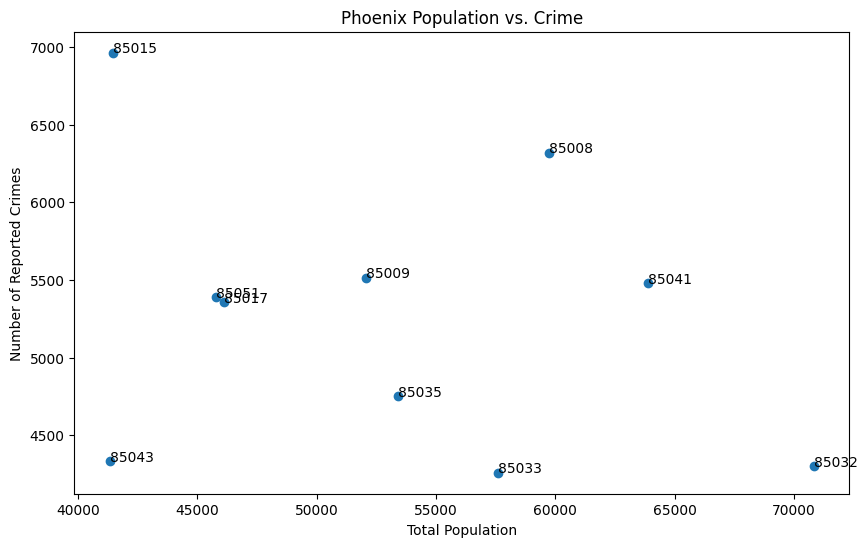

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(combined['pop_total_est'], combined['crimes'])

for i in range(len(combined)):
    plt.annotate(
        combined['ZIP'].iloc[i],
        (combined['pop_total_est'].iloc[i], combined['crimes'].iloc[i])
    )

plt.xlabel('Total Population')
plt.ylabel('Number of Reported Crimes')
plt.title('Phoenix Population vs. Crime')

plt.show()

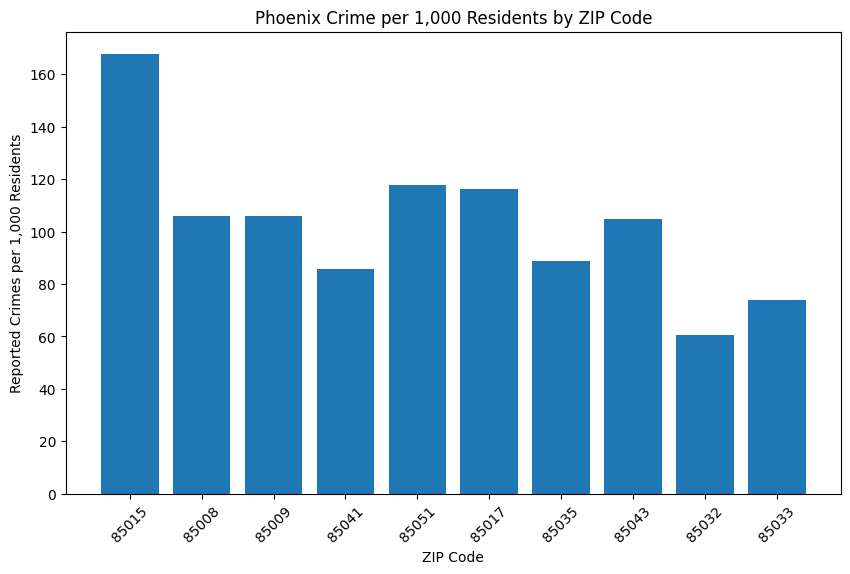

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(combined['ZIP'], combined['crimes_per_1000'])

plt.xlabel('ZIP Code')
plt.ylabel('Reported Crimes per 1,000 Residents')
plt.title('Phoenix Crime per 1,000 Residents by ZIP Code')

plt.xticks(rotation=45)

plt.show()

In [34]:
combined.to_csv(
    '/content/drive/MyDrive/phoenix_crime_population.csv',
    index=False
)